100%|██████████| 30.8k/30.8k [00:00<00:00, 10.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/mohdshahnawazaadil/sales-prediction-dataset/versions/1

--- First 5 Rows of the Dataset ---
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Training the Sales Prediction model...



--- Model Performance Metrics ---
Mean Absolute Error (MAE): 0.92
Root Mean Squared Error (RMSE): 1.20
R-squared Score ($R^2$): 0.9535


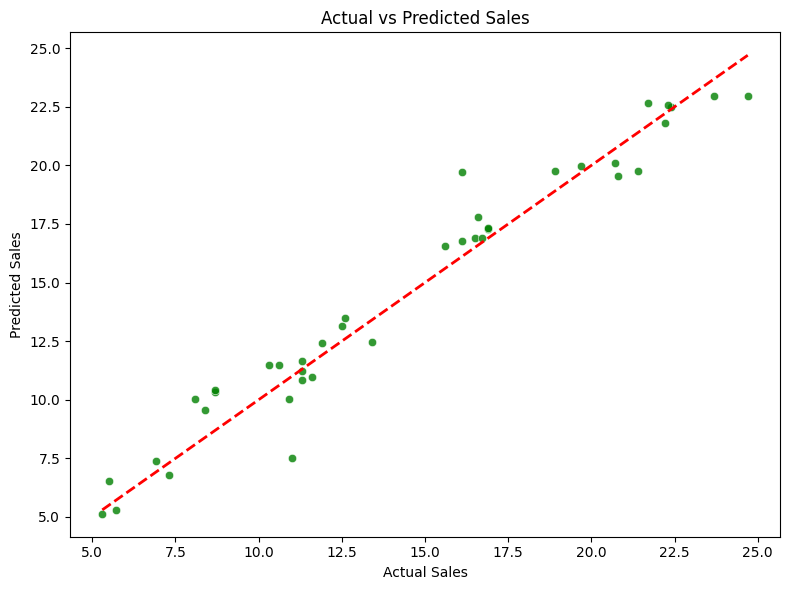


Task 4 Execution Completed Successfully!


In [1]:
!pip install kagglehub -q

import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings('ignore')
print("Downloading Sales Prediction dataset from Kaggle...")

# 1. Download dataset using kagglehub
path = kagglehub.dataset_download("mohdshahnawazaadil/sales-prediction-dataset")
print("Path to dataset files:", path)

# 2. Locate and load the CSV file into Pandas
files = os.listdir(path)
csv_file_name = [f for f in files if f.endswith('.csv')][0]
csv_file_path = os.path.join(path, csv_file_name)

df = pd.read_csv(csv_file_path)
df.columns = df.columns.str.strip()

print("\n--- First 5 Rows of the Dataset ---")
print(df.head())

# 3. Data Cleaning & Feature Selection
# Drop missing values if any
df = df.dropna()

# Drop non-numeric identifier columns if they exist (e.g., Unnamed or ID columns)
for col in df.columns:
    if 'unnamed' in col.lower() or 'id' in col.lower():
        df = df.drop(columns=[col])

# Assume the target variable is 'Sales' and features are advertising spend (TV, Radio, Newspaper, etc.)
target_col = [col for col in df.columns if 'sale' in col.lower()][0]
X = df.drop(columns=[target_col])
y = df[target_col]

# Handle categorical features via One-Hot Encoding if present
X = pd.get_dummies(X, drop_first=True)

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Model Training (Random Forest Regressor)
print("\nTraining the Sales Prediction model...")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 6. Evaluation
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n--- Model Performance Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score ($R^2$): {r2:.4f}")

# 7. Visualization: Feature Importance or Actual vs Predicted Sales
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.8, color='green')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Sales')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.tight_layout()
plt.show()

print("\nTask 4 Execution Completed Successfully!")